In [4]:
%load_ext autoreload
%autoreload 2

In [ ]:
import pandas as pd
import numpy as np
import json
import random
from xgboost import XGBRegressor, XGBClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, mean_squared_error, accuracy_score
from sklearn.model_selection import GridSearchCV, train_test_split
from imblearn.under_sampling import RandomUnderSampler
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from src.modelos import MLP_regresion, MLP_clasificacion
from src.utils import df_features_to_numpy, df_target_to_numpy, run_experiment_pytorch_clasificacion, run_experiment_pytorch_regresion, permutation_importance_pytorch, grid_search_rf_clasificacion, evaluar_modelo_rf_clasificacion, grid_search_xgb_clasificacion, evaluar_modelo_xgb_clasificacion, run_grid_search_pytorch_regresion, run_grid_search_pytorch_clasificacion
from src.splitting import split_estratificado_autor
from src.metricas import tabla_metricas, evaluar_metricas_clasificacion, evaluar_metricas_regresion
from src.graficos import plot_confusion_matrix, plot_learning_curves_xgboost_regression, plot_learning_curves_xgboost_classification, plot_feature_importance_xgb, plot_learning_curves_randomforest_regression, plot_learning_curves_randomforest_classification, plot_feature_importance_rf, plot_feature_importance_pytorch

# Cargo el dataset ya procesado

In [ ]:
#LEO VAL
chunks_val = pd.read_json("set_val_1.json", lines=True, chunksize=100_000)
chunk_list = []
for chunk in chunks_val:
    chunk_list.append(chunk)
df_val = pd.concat(chunk_list, ignore_index=True)

#LEO TRAIN
chunks_train = pd.read_json("set_train_1.json", lines=True, chunksize=100_000)
chunk_list = []
for chunk in chunks_train:
    chunk_list.append(chunk)
df_train = pd.concat(chunk_list, ignore_index=True)

## Preparacion de los datos
Elegimos las features con las que nos vamos a quedar para esta etapa. Convertimos los datafreames a arrays de numpy, y escalamos los datos. 

In [ ]:
generos = ["fiction", "non fiction", "fantasy", "science fiction", "mystery", "thriller", "romance", "horror", "historical", "young adult", "children", "adventure", "contemporary", "dystopian", "paranormal", "urban", "crime", "biography", "memoir", "self help", "history", "psychology", "poetry", "classics", "graphic novel", "short stories", "humor", "religion"]
features = ["is_series", "publication_year", "num_pages", 'AUDIO', 'COMIC', 'EBOOK', 'UNKNOWN', 'HARDCOVER', 'OTHER', 'PAPERBACK', "language_code_ang", "language_code_en", "language_code_en-CA", "language_code_en-GB", "language_code_en-US", "language_code_eng", "language_code_enm", "language_code_gem", "language_code_sco", "cantidad_generos"] + generos 

#Me quedo solo con las features necesarias para el modelo base y las estandarizo
dfs = [df_train, df_val]
y_train_regresion, y_val_regresion = df_target_to_numpy("average_rating", dfs)
y_train_clasificacion, y_val_clasificacion = df_target_to_numpy("estrellas", dfs)
X_train, X_val = df_features_to_numpy(features, dfs)

#Estandarizo los datos
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val) #escala X_val con los valores sacados de X_train

### Variables que necesito para hacer grid search
Creo un subset estratificado (por estrellas) de 100mil muestras. Este subset nos sirve para hacer un grid search manteniendo las distribuciones pero sin que tome mucho tiempo ni capacidad de computo. 

In [ ]:
#Defino las variables que necesito para grid search, tanto para random forest como para xgboost
X_sub, _, y_sub_regresion, _, y_sub_clasificacion, _ = train_test_split(X_train_scaled, y_train_regresion, y_train_clasificacion, train_size=100000, stratify=y_train_clasificacion, random_state=42)

parametros_grid_search_rf = {
    "n_estimators": [100, 200, 300],
    "max_depth": [5, 10, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

parametros_grid_search_xgb = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
}

parametros_grid_search_rn = {
    "capas_ocultas": [[128, 64], [256, 128], [256, 128, 64]],
    "dropout": [0.0, 0.2, 0.4],
    "lr": [0.01, 0.001, 0.0001],
    "funcion_activacion": [nn.ReLU, nn.LeakyReLU]
}

### Preparo los datos que voy a usar en los modelos cuando quiera usar tecnicas de rebalanceo

In [6]:
#Hago undersampling para los datos de train, uso el valor optimo encontrado en ModeloBase
cant_datos_deseada = {4: 225000}
undersampling = RandomUnderSampler(sampling_strategy = cant_datos_deseada, random_state = 42)
X_train_undersampling, y_train_undersampling = undersampling.fit_resample(X_train_scaled, y_train_clasificacion) 

#Hago undersampling para el subset usado en grid search
cant_datos_deseada_sub = {4: 50000} 
undersampling = RandomUnderSampler(sampling_strategy = cant_datos_deseada_sub, random_state = 42)
X_sub_undersampling, y_sub_clasificacion_undersampling = undersampling.fit_resample(X_sub, y_sub_clasificacion) 

El valor optimo encontrado en ModeloBase para la cantidad de datos deseada de la clase 4 post undersampling es 225000, lo que corresponde aproximadamente al 50% del dataset de train. <br>
Entonces, para la cantidad de datos deseada de la clase 4 para el subset de grid search, tomo como valor el 50% de los datos de X_sub (subset de train). Para el subset elijo 100000 muestras, por lo que la cantidad de datos deseada de la clase 4 post undersampling va a ser 50000. 

Guia de variables para clasificacion:
<br> <br>
**X_sub**: conjunto utilizado en grid search sin undersampling <br>
**X_sub_undersampling**: conjunto utilizado en grid search con undersampling <br>
**X_train_scaled**: conjunto utilizado en el entrenamiento del modelo sin undersampling <br>
**X_train_undersampling**: conjunto utilizado en el entrenamiento del modelo con undersampling <br>
<br>
**y_sub_clasificacion**: conjunto utilizado en grid search sin undersampling <br>
**y_sub_clasificacion_undersampling**: conjunto utilizado en grid search con undersampling <br>
**y_train_clasificacion**: conjunto utilizado en el entrenamiento del modelo sin undersampling <br>
**y_train_undersampling**: conjunto utilizado en el entrenamiento del modelo con undersampling <br>

## Random Forest con features basicas - Regresion

Grid Search: tomo una muestra de 100 mil datos para encontrar los mejores hiperparametros, una vez encontrados estos valores reentreno con todos los datos

In [7]:
RandomForestGridSearchRegresion = RandomForestRegressor(random_state=42)
grid = GridSearchCV(estimator = RandomForestGridSearchRegresion, param_grid = parametros_grid_search_rf, cv = 3, scoring="r2", n_jobs=-1, verbose=2)
grid.fit(X_sub, y_sub_regresion)
mejores_parametros = grid.best_params_
print(f"Mejores parametros: {mejores_parametros}")
print(f"Mejor R² CV: {grid.best_score_}")

Fitting 3 folds for each of 162 candidates, totalling 486 fits
Mejores parametros: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 300}
Mejor R² CV: 0.20262936991623834


In [8]:
modeloRandomForestRegresion = RandomForestRegressor(**mejores_parametros, random_state = 42)
modeloRandomForestRegresion.fit(X_train_scaled, y_train_regresion)

y_pred_train_modeloRandomForestRegresion = modeloRandomForestRegresion.predict(X_train_scaled)
y_pred_val_modeloRandomForestRegresion = modeloRandomForestRegresion.predict(X_val_scaled)

metricas_train = evaluar_metricas_regresion(y_pred_train_modeloRandomForestRegresion, y_train_regresion)
metricas_val = evaluar_metricas_regresion(y_pred_val_modeloRandomForestRegresion, y_val_regresion)
tabla_metricas_rf_regresion = tabla_metricas(metricas_train, metricas_val, ["MSE", "RMSE", "MAE", "R²"])
print(tabla_metricas_rf_regresion)

         Train  Validation
MSE   0.094564    0.111370
RMSE  0.307512    0.333722
MAE   0.235520    0.256799
R²    0.331328    0.214816


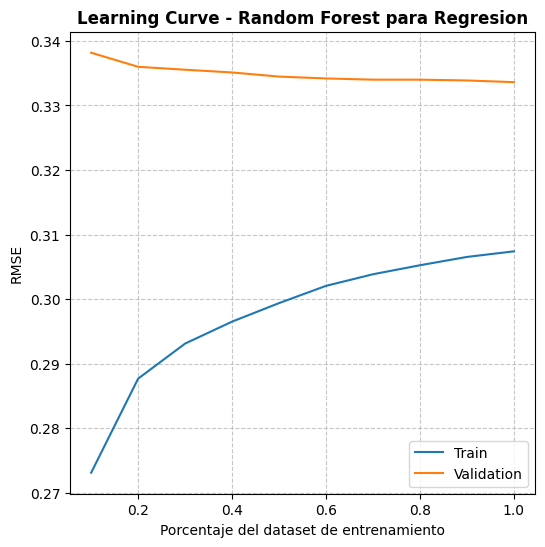

In [9]:
plot_learning_curves_randomforest_regression(X_train_scaled, y_train_regresion, X_val_scaled, y_val_regresion, **mejores_parametros)

Analizamos la feature importance:

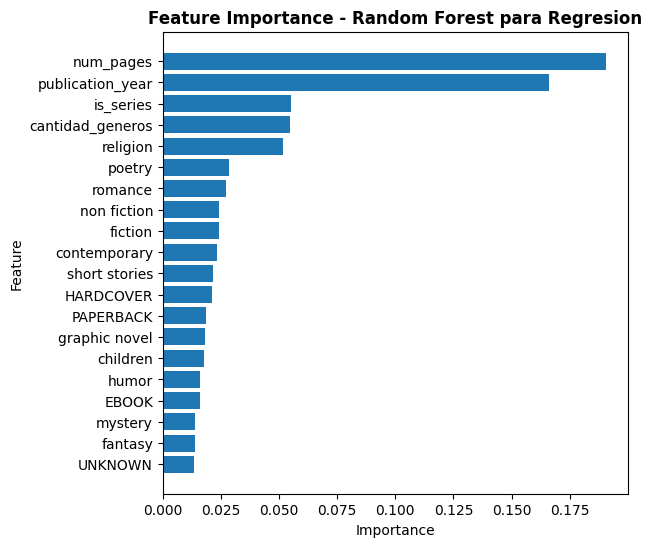

In [10]:
importancias_coef_rf_reg = pd.DataFrame({"feature": features, "importance": modeloRandomForestRegresion.feature_importances_})
importancias_coef_rf_reg = importancias_coef_rf_reg.sort_values("importance", ascending = False)
plot_feature_importance_rf(importancias_coef_rf_reg, "para Regresion")

Observando las metricas y la learning curve, notamos que el modelo generaliza bastante bien, obtenemos valores parecidos en train y validation. <br> Los errores obtenidos no son grandes, pero tampoco ideales. Poniendo esto en relacion con la feature importance, notamos que las features no aportan demasiada informacion, lo que podria explicar los resultados de las metricas. 

## Random Forest con features basicas - Clasificacion

Para tratar con el desbalanceo de clases, implemento dos metodos. En primer lugar cost re-weight + undersampling (con los pesos y proporciones optimos encontrados en Modelo_Base), y despues unicamente cost re-weight.

In [ ]:
pesos_undersampling_cost = {1:8, 2:10, 3:2, 4:1, 5:3}
pesos_cost = {1:8, 2:2, 3:2, 4:1, 5:5}

### Cost + undersampling

Fitting 3 folds for each of 162 candidates, totalling 486 fits
Mejores parametros: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 100}
Mejor F1 CV: 0.30151723731641744
              Train  Validation
Accuracy   0.784614    0.768823
Precision  0.787792    0.298183
Recall     0.409233    0.288730
F1         0.464159    0.292752


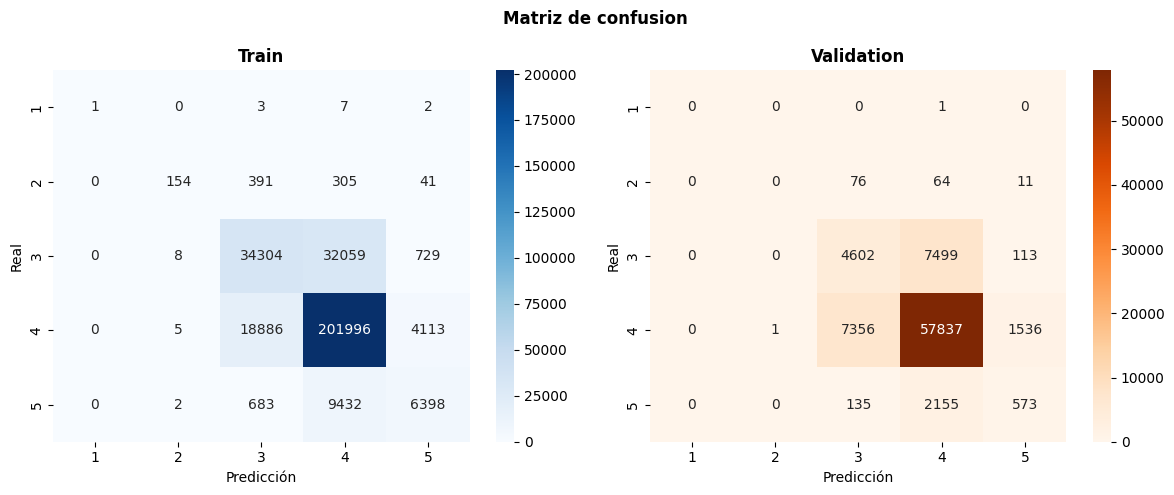

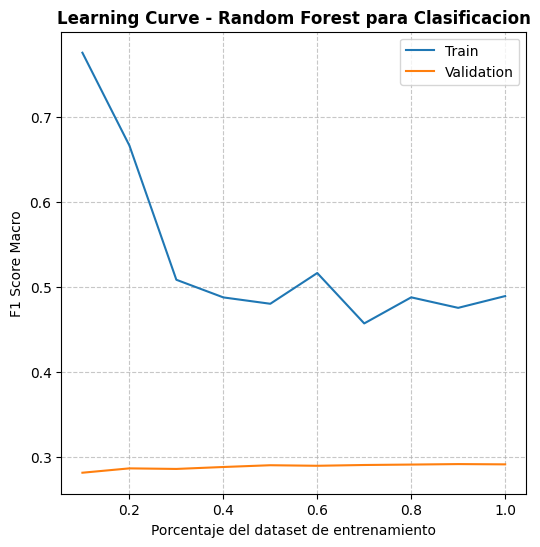

In [ ]:
mejores_parametros = grid_search_rf_clasificacion(pesos_undersampling_cost, X_sub_undersampling, y_sub_clasificacion_undersampling, parametros_grid_search_rf)
tabla_metricas_rf_clasificacion_undersampling_cost, modeloRandomForestClasificacion = evaluar_modelo_rf_clasificacion(mejores_parametros, pesos_undersampling_cost, X_train_undersampling, y_train_undersampling, X_val_scaled, y_val_clasificacion)
plot_learning_curves_randomforest_classification(X_train_undersampling, y_train_undersampling, X_val_scaled, y_val_clasificacion, pesos = pesos_undersampling_cost, **mejores_parametros)

Analizamos la feature importance:

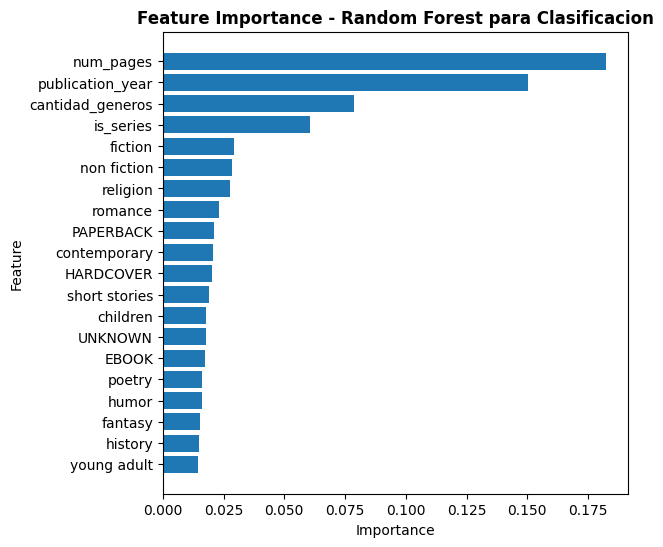

In [13]:
importancias_coef_rf_clasf = pd.DataFrame({"feature": features, "importance": modeloRandomForestClasificacion.feature_importances_})
importancias_coef_rf_clasf = importancias_coef_rf_clasf.sort_values("importance", ascending = False)
plot_feature_importance_rf(importancias_coef_rf_clasf, "para Clasificacion")

Observando las matrices de confusion, notamos que el modelo logra predecir algunas veces las clases 1 y 2, pero los numeros siguen siendo bajos. <br>
Analizando las metricas, notamos que el modelo generaliza bastante bien para las clases mayoritarias, pero pierde capacidad para identificar correctamente las clases minoritarias, especialmente cuando se evalua el modelo con datos no vistos. Esto concuerda con los resultados de precision, recall y f1. El accuracy permanece constante por el desbalance de clases. 

### Cost sin undersampling

Fitting 3 folds for each of 162 candidates, totalling 486 fits
Mejores parametros: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 100}
Mejor F1 CV: 0.25490856765647946
              Train  Validation
Accuracy   0.823101    0.804268
Precision  0.369386    0.319899
Recall     0.291973    0.258228
F1         0.305782    0.266799


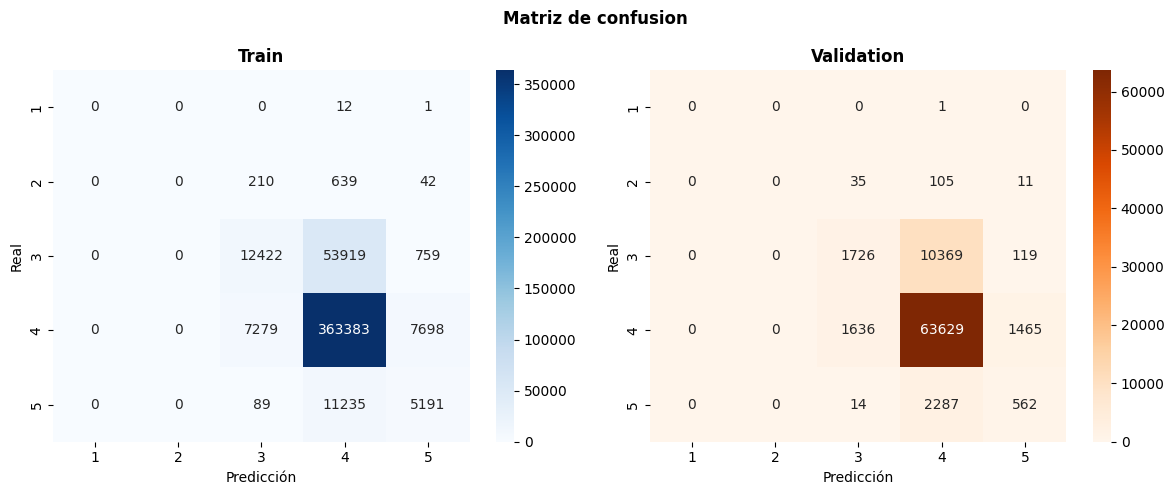

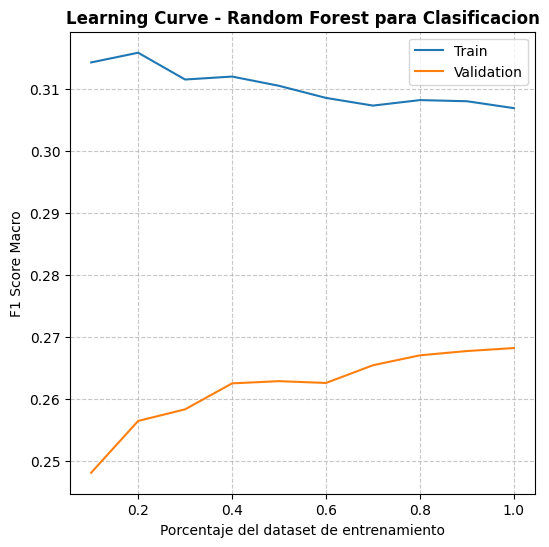

In [ ]:
mejores_parametros = grid_search_rf_clasificacion(pesos_cost, X_sub, y_sub_clasificacion, parametros_grid_search_rf)
tabla_metricas_rf_clasificacion_cost, modeloRandomForestClasificacion = evaluar_modelo_rf_clasificacion(mejores_parametros, pesos_cost, X_train_scaled, y_train_clasificacion, X_val_scaled, y_val_clasificacion)
plot_learning_curves_randomforest_classification(X_train_scaled, y_train_clasificacion, X_val_scaled, y_val_clasificacion, pesos = pesos_cost, **mejores_parametros)

Analizamos la feature importance

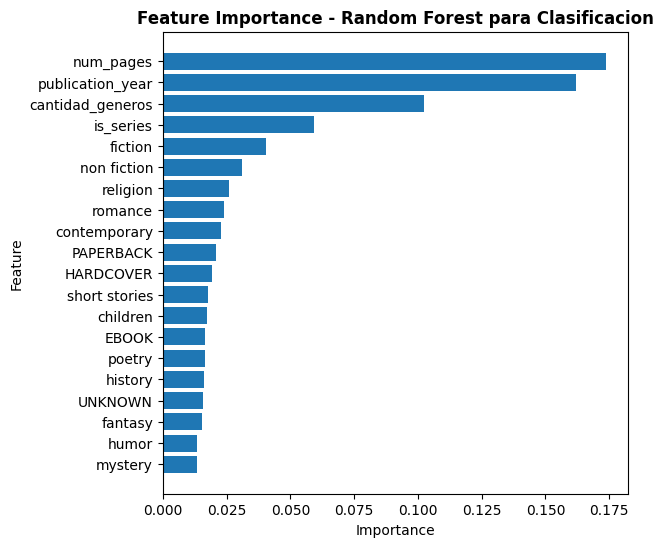

In [15]:
importancias_coef_rf_clasf = pd.DataFrame({"feature": features, "importance": modeloRandomForestClasificacion.feature_importances_})
importancias_coef_rf_clasf = importancias_coef_rf_clasf.sort_values("importance", ascending = False)
plot_feature_importance_rf(importancias_coef_rf_clasf, "para Clasificacion")

Con este rebalanceo obtenemos una mejor generalizacion y un mejor resultado en accuracy, pero peores valores de f1, accuracy y precision. 

## XGBoost con features basicas - Regresion

Empiezo con grid search para buscar los mejores hiperparametros

In [8]:
XGBoostGridSearchRegresion = XGBRegressor(objective = "reg:squarederror", device = "cuda", tree_method = "hist", random_state = 42)
grid = GridSearchCV(estimator = XGBoostGridSearchRegresion, param_grid = parametros_grid_search_xgb, cv = 3, scoring = "r2", n_jobs = 1, verbose = 1)
grid.fit(X_sub, y_sub_regresion)
mejores_parametros = grid.best_params_
print(f"Mejores parametros: {mejores_parametros}")
print(f"Mejor R² CV: {grid.best_score_}")

Fitting 3 folds for each of 108 candidates, totalling 324 fits


/home/czava/.local/lib/python3.10/site-packages/xgboost/core.py:751: UserWarning: [01:39:32] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


Mejores parametros: {'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 7, 'n_estimators': 300, 'subsample': 0.8}
Mejor R² CV: 0.21341216369890595


In [9]:
#subsample --> en cada arbol solo usa una fraccion de las filas (muestras) --> ayuda a descorrelacionar
#colsample_bytree --> solo usa una fraccion de las columnas (features) --> ayuda a descorrelacionar
modeloXGBoostRegresion = XGBRegressor(**mejores_parametros, objective = "reg:squarederror", device = "cuda", tree_method = "hist", random_state = 42) #MInimiza MSE
modeloXGBoostRegresion.fit(X_train_scaled, y_train_regresion) #XGBoost no requiere obligatoriamnete que se escalen los valores, pero lo hag para poder comprar la feature importance

y_pred_train_modeloXGBoostRegresion = modeloXGBoostRegresion.predict(X_train_scaled)
y_pred_val_modeloXGBoostRegresion = modeloXGBoostRegresion.predict(X_val_scaled)

metricas_train = evaluar_metricas_regresion(y_pred_train_modeloXGBoostRegresion, y_train_regresion)
metricas_val = evaluar_metricas_regresion(y_pred_val_modeloXGBoostRegresion, y_val_regresion)
tabla_metricas_xgboost_regresion = tabla_metricas(metricas_train, metricas_val, ["MSE", "RMSE", "MAE", "R²"])
print(tabla_metricas_xgboost_regresion)

         Train  Validation
MSE   0.106970    0.109663
RMSE  0.327063    0.331154
MAE   0.251293    0.254541
R²    0.243601    0.226855


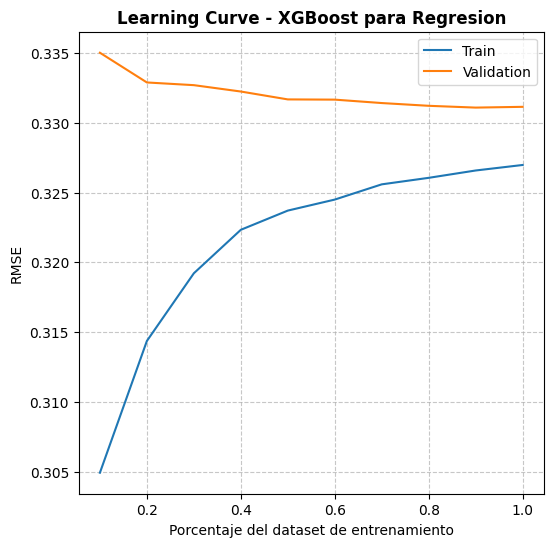

In [10]:
plot_learning_curves_xgboost_regression(X_train_scaled, y_train_regresion, X_val_scaled, y_val_regresion, **mejores_parametros)

Analizamos las feature importance:

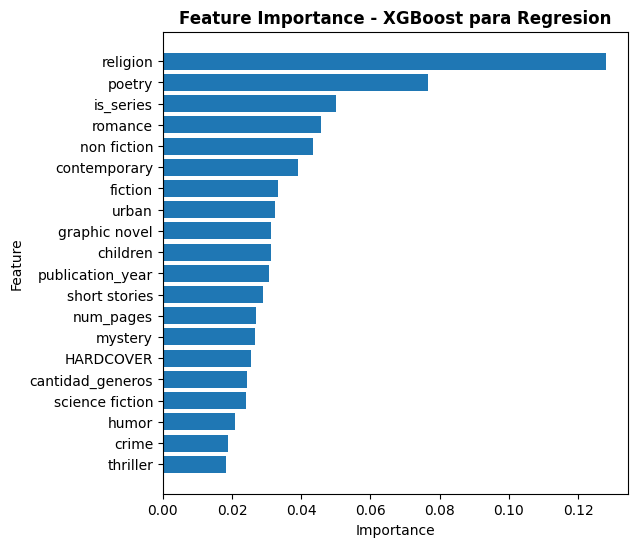

In [11]:
importancias_coef_xgb_reg = pd.DataFrame({"feature": features, "importance": modeloXGBoostRegresion.feature_importances_})
importancias_coef_xgb_reg = importancias_coef_xgb_reg.sort_values("importance", ascending = False)
plot_feature_importance_xgb(importancias_coef_xgb_reg, "para Regresion")

Con XGBoost obtenemos resultados muy similares a los que habiamos tenido con Random Forest. Se logra una buena generalizacion pero nuestras features no logran explicar correctamente la variabilidad del rating. 

## XGBoost con features basicas - Clasificacion

XGBoost solo trabaja con clases empezando desde 0, (aunque nuestras estrellas vayan de 1 a 5). Para poder entrenar con este modelo, transformo temporalmente el target restando 1. Luego, para volver a las clases normales, sumo 1 a la prediccion.

In [ ]:
#Transformaciones temporales
y_sub_undersampling_temp = y_sub_clasificacion_undersampling - 1
y_sub_temp = y_sub_clasificacion - 1
y_train_undersampling_temp = y_train_undersampling - 1
y_train_temp = y_train_clasificacion - 1

#Exactamente los mismos pesos que antes pero con las clases - 1
pesos_undersampling_cost_xgb = {0:8, 1:10, 2:2, 3:1, 4:3}
pesos_cost_xgb = {0:8, 1:2, 2:2, 3:1, 4:5}

### Cost + undersampling

Fitting 3 folds for each of 108 candidates, totalling 324 fits


[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=3, n_estimators=100, subsample=0.8; total time=   0.5s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=3, n_estimators=100, subsample=0.8; total time=   0.4s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=3, n_estimators=100, subsample=0.8; total time=   0.4s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=3, n_estimators=100, subsample=1.0; total time=   0.4s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=3, n_estimators=100, subsample=1.0; total time=   0.4s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=3, n_estimators=100, subsample=1.0; total time=   0.4s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=3, n_estimators=200, subsample=0.8; total time=   0.7s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=3, n_estimators=200, subsample=0.8; total time=   0.7s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=3, n_estima

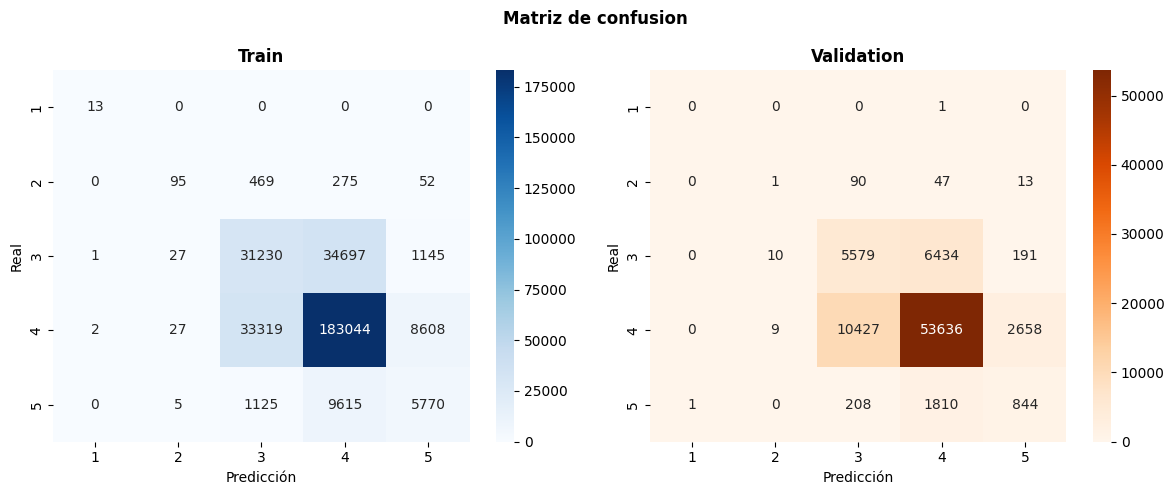

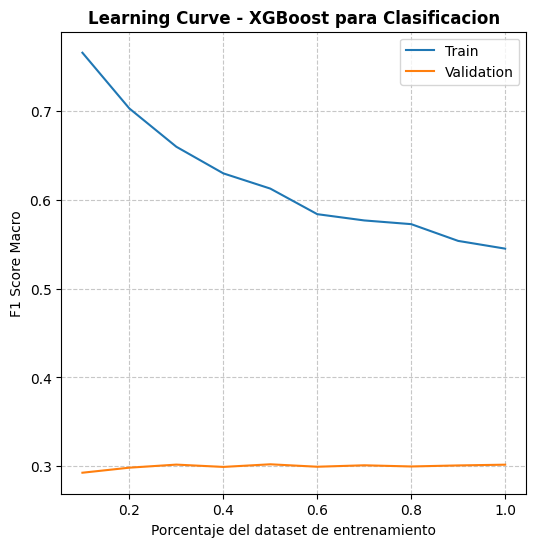

In [ ]:
mejores_parametros = grid_search_xgb_clasificacion(pesos_undersampling_cost_xgb, X_sub_undersampling, y_sub_undersampling_temp, parametros_grid_search_xgb)
tabla_metricas_xgb_clasificacion_undersampling_cost, modeloXGBoostClasificacion = evaluar_modelo_xgb_clasificacion(mejores_parametros, pesos_undersampling_cost_xgb, X_train_undersampling, y_train_undersampling_temp, X_val_scaled, y_val_clasificacion)
plot_learning_curves_xgboost_classification(X_train_undersampling, y_train_undersampling, X_val_scaled, y_val_clasificacion, pesos = pesos_undersampling_cost_xgb, **mejores_parametros)

Analizamos las feature importance:

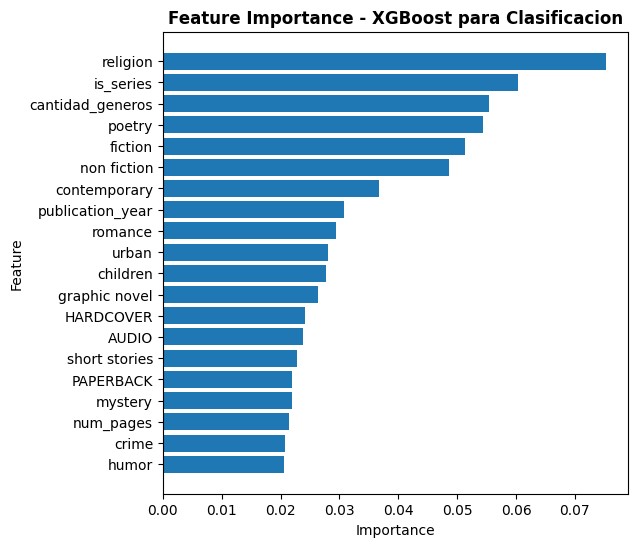

In [15]:
importancias_coef_xgb_clasf = pd.DataFrame({"feature": features, "importance": modeloXGBoostClasificacion.feature_importances_})
importancias_coef_xgb_clasf = importancias_coef_xgb_clasf.sort_values("importance", ascending = False)
plot_feature_importance_xgb(importancias_coef_xgb_clasf, "para Clasificacion")

Al igual que en random forest, con cost y undersampling se obtienen muy buenas metricas en train, pero estas decaen al aplicarlas a datos nuevos. Sin embargo, estos ultimos resultados se mantienen similares a los de otros modelos. 

### Cost sin undersampling

Fitting 3 folds for each of 108 candidates, totalling 324 fits
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=3, n_estimators=100, subsample=0.8; total time=   0.5s


[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=3, n_estimators=100, subsample=0.8; total time=   0.5s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=3, n_estimators=100, subsample=0.8; total time=   0.5s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=3, n_estimators=100, subsample=1.0; total time=   0.5s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=3, n_estimators=100, subsample=1.0; total time=   0.5s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=3, n_estimators=100, subsample=1.0; total time=   0.5s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=3, n_estimators=200, subsample=0.8; total time=   0.8s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=3, n_estimators=200, subsample=0.8; total time=   0.8s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=3, n_estimators=200, subsample=0.8; total time=   0.8s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=3, n_estima

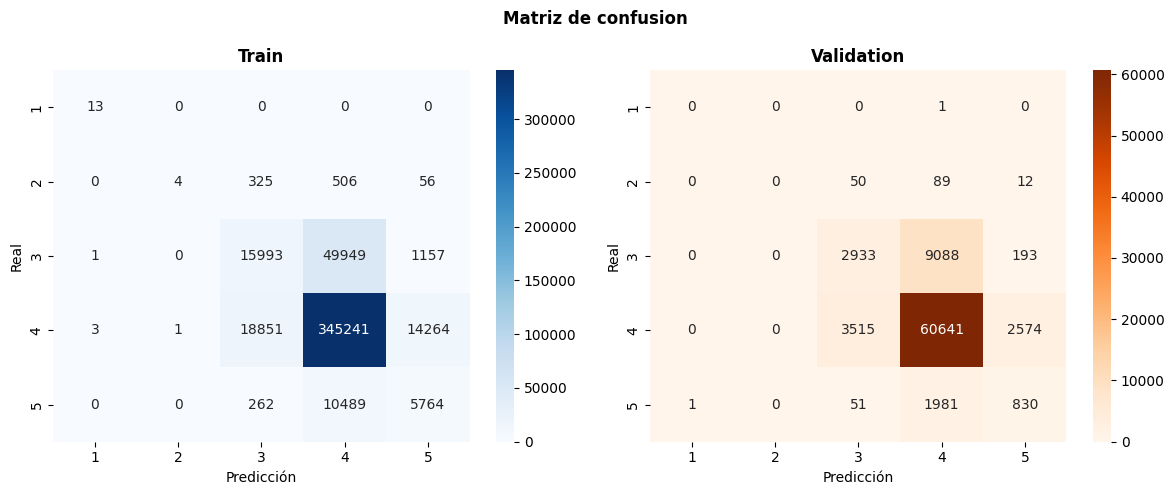

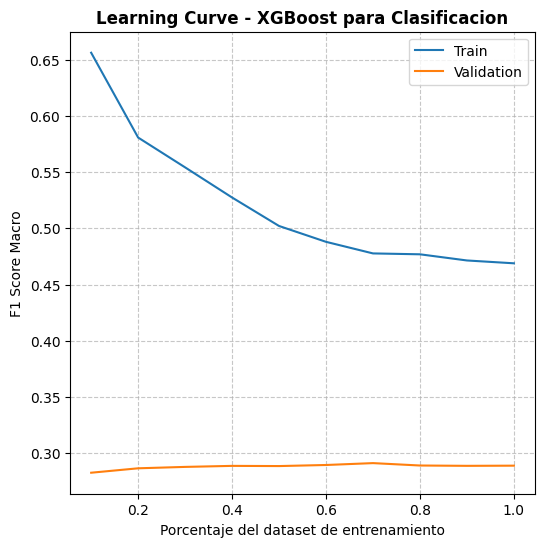

In [ ]:
mejores_parametros = grid_search_xgb_clasificacion(pesos_cost_xgb, X_sub, y_sub_temp, parametros_grid_search_xgb)
tabla_metricas_xgb_clasificacion_cost, modeloXGBoostClasificacion = evaluar_modelo_xgb_clasificacion(mejores_parametros, pesos_cost_xgb, X_train_scaled, y_train_temp, X_val_scaled, y_val_clasificacion)
plot_learning_curves_xgboost_classification(X_train_scaled, y_train_clasificacion, X_val_scaled, y_val_clasificacion, pesos = pesos_cost_xgb, **mejores_parametros)

Analizamos las feature importance:

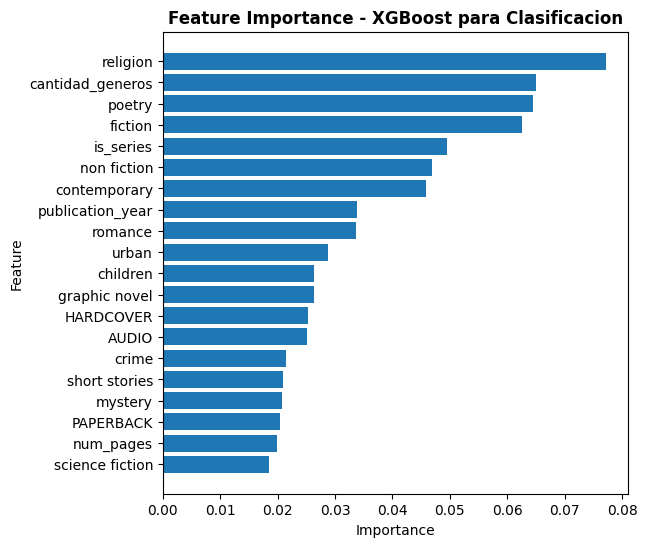

In [17]:
importancias_coef_xgb_clasf = pd.DataFrame({"feature": features, "importance": modeloXGBoostClasificacion.feature_importances_})
importancias_coef_xgb_clasf = importancias_coef_xgb_clasf.sort_values("importance", ascending = False)
plot_feature_importance_xgb(importancias_coef_xgb_clasf, "para Clasificacion")

Obtenemos el mismo problema que con la anterior tecnica de rebalanceo. 

## Red neuronal con features basicas - Regresion

In [18]:
if torch.cuda.is_available():
  device = "cuda"
else:
  device = "cpu"

Grid search

In [ ]:
mejor_r2 = -np.inf
mejores_parametros = None

for capas_ocultas in parametros_grid_search_rn["capas_ocultas"]:
    for dropout in parametros_grid_search_rn["dropout"]:
        for lr in parametros_grid_search_rn["lr"]:
            for activacion in parametros_grid_search_rn["funcion_activacion"]:

                modelo = MLP_regresion(input_size = X_sub.shape[1], hidden_layers=capas_ocultas, activation=activacion, dropout=dropout).to(device)
                r2 = run_grid_search_pytorch_regresion(modelo=modelo, learning_rate = lr, model_name="MLP Regresion", X_train=X_sub, y_train=y_sub_regresion, X_val=X_val_scaled, y_val=y_val_regresion, device=device, epochs=30)
                if r2 > mejor_r2:
                    mejor_r2 = r2
                    mejores_parametros = {"capas_ocultas": capas_ocultas, "dropout": dropout, "lr": lr, "activacion": activacion}

print(f"\nMejores parametros: {mejores_parametros}")

PyTorch: 100%|██████████| 30/30 [00:44<00:00,  1.50s/epoca, epoch=30]



Mejores parametros: {'capas_ocultas': [128, 64], 'dropout': 0.2, 'lr': 0.01, 'activacion': <class 'torch.nn.modules.activation.ReLU'>}


PyTorch:   0%|          | 0/100 [00:00<?, ?epoca/s]

PyTorch: 100%|██████████| 100/100 [11:09<00:00,  6.69s/epoca, epoch=100]


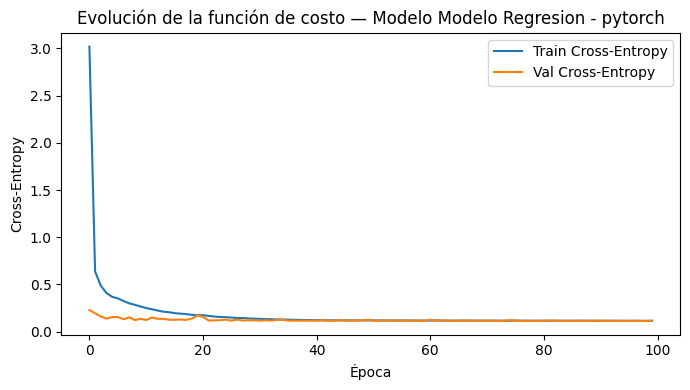

         Train  Validation
MSE   0.116485    0.116650
RMSE  0.341299    0.341541
MAE   0.266608    0.266592
R²    0.176318    0.177591


In [20]:
modelo_regresion = MLP_regresion(input_size = X_train_scaled.shape[1], hidden_layers = mejores_parametros["capas_ocultas"], activation = mejores_parametros["activacion"], dropout = mejores_parametros["dropout"]).to(device)
metricas_train, metricas_val = run_experiment_pytorch_regresion(modelo_regresion, "Modelo Regresion", X_train_scaled, y_train_regresion, X_val_scaled, y_val_regresion, device, learning_rate = mejores_parametros["lr"])
tabla_metricas_mlp_regresion = tabla_metricas(metricas_train, metricas_val, ["MSE", "RMSE", "MAE", "R²"])
print(tabla_metricas_mlp_regresion)

Las redes neuronales con pytorch no tienen un atributo para acceder a la feature importance, a diferencia de XGBoost o Random Forest. Para simular esto, se agarra por separado cada feature y se la mezcla (de esta manera se descorrelaciona la salida del modelo con esta feature). Despues, se predice con esa nueva feature y se evalua la diferencia con el X original. A mayor diferencia mayor impacto tiene la feature. 

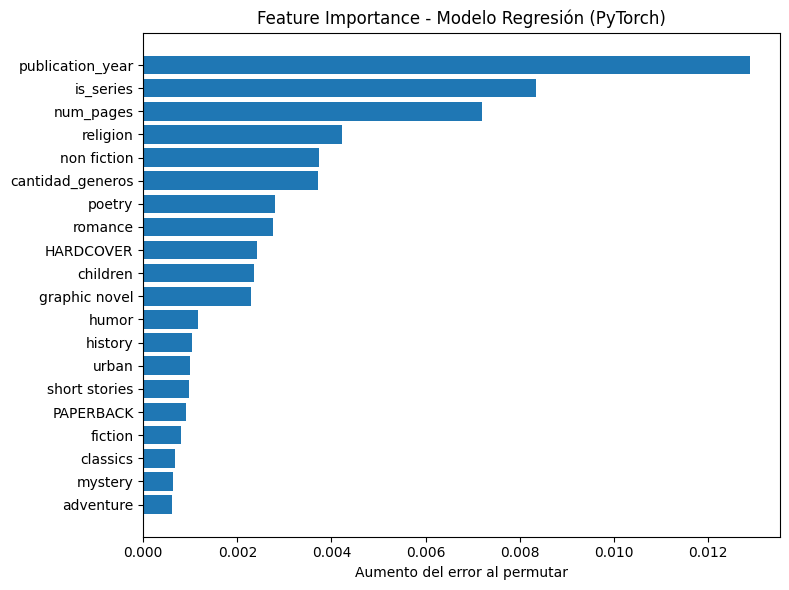

In [21]:
feature_importance_regresion = permutation_importance_pytorch(modelo_regresion, X_val_scaled, y_val_regresion, features, device,metric_fn=mean_squared_error, higher_is_better=False, n_repeats=10)
plot_feature_importance_pytorch(feature_importance_regresion, top_n=20, title="Feature Importance - Modelo Regresión (PyTorch)")

Las metricas resultan muy consistentes en train y validation, generaliza correctamente. Sin embargo, al igual que en random forest y xgboost, el R² se mantiene en 0.2, un valor bastante bajo. 

## Red neuronal con features basicas - Clasificacion

La red neuronal tambien necesita que las clases empiecen en 0, por lo que adentro de las funciones manejo los conjuntos de y restando 1, y luego sumando 1 a la prediccion. 

### Cost sin undersampling

In [ ]:
mejor_f1 = -np.inf
mejores_parametros = None

for capas_ocultas in parametros_grid_search_rn["capas_ocultas"]:
    for dropout in parametros_grid_search_rn["dropout"]:
        for lr in parametros_grid_search_rn["lr"]:
            for activacion in parametros_grid_search_rn["funcion_activacion"]:

                print(f"Probando: {capas_ocultas}, dropout={dropout}, lr={lr}, activacion={activacion.__name__}")
                modelo = MLP_clasificacion(input_size=X_sub.shape[1], hidden_layers=capas_ocultas, n_classes=5, activation=activacion, dropout=dropout).to(device)

                f1 = run_grid_search_pytorch_clasificacion(modelo=modelo, learning_rate=lr, model_name="MLP Clasificacion", X_train=X_sub, y_train=y_sub_clasificacion, X_val=X_val_scaled, y_val=y_val_clasificacion, device=device, epochs=30, pesos = pesos_cost)

                if f1 > mejor_f1:
                    mejor_f1 = f1
                    mejores_parametros = {"capas_ocultas": capas_ocultas, "dropout": dropout, "lr": lr, "activacion": activacion}

print(f"\nMejores parametros: {mejores_parametros}")

Probando: [128, 64], dropout=0.0, lr=0.01, activacion=ReLU


PyTorch:   0%|          | 0/30 [00:00<?, ?epoca/s]

PyTorch: 100%|██████████| 30/30 [00:48<00:00,  1.61s/epoca, epoch=30]


Probando: [128, 64], dropout=0.0, lr=0.01, activacion=LeakyReLU


PyTorch: 100%|██████████| 30/30 [00:44<00:00,  1.47s/epoca, epoch=30]


...

Probando: [256, 128, 64], dropout=0.4, lr=0.0001, activacion=ReLU


PyTorch: 100%|██████████| 30/30 [00:53<00:00,  1.78s/epoca, epoch=30]


Probando: [256, 128, 64], dropout=0.4, lr=0.0001, activacion=LeakyReLU


PyTorch: 100%|██████████| 30/30 [00:46<00:00,  1.56s/epoca, epoch=30]



Mejores parametros: {'capas_ocultas': [256, 128], 'dropout': 0.0, 'lr': 0.001, 'activacion': <class 'torch.nn.modules.activation.LeakyReLU'>}


PyTorch:   0%|          | 0/100 [00:00<?, ?epoca/s]

PyTorch: 100%|██████████| 100/100 [11:52<00:00,  7.12s/epoca, epoch=100]


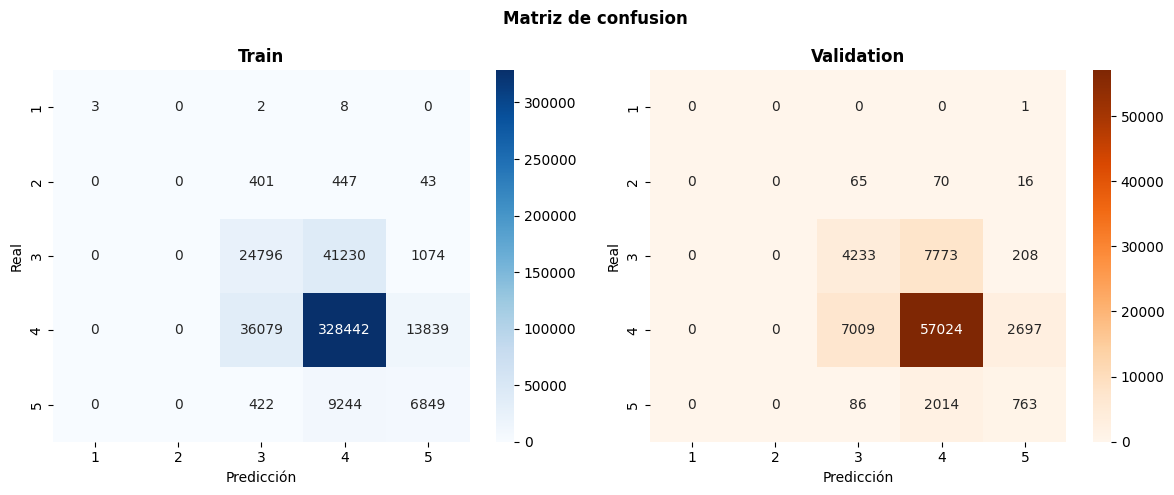

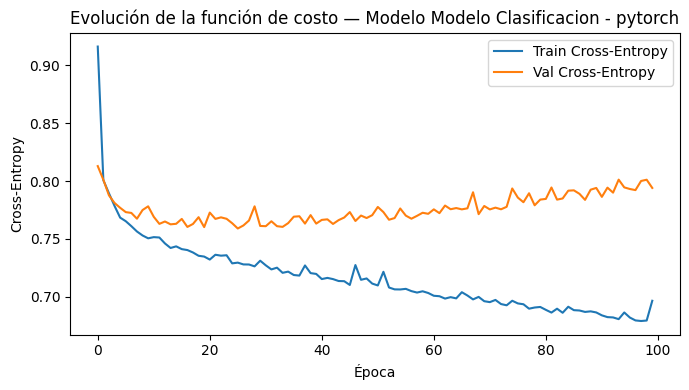

              Train  Validation
Accuracy   0.777935    0.756720
Precision  0.516347    0.286244
Recall     0.376618    0.293524
F1_score   0.396881    0.289051


In [23]:
modelo_clasificacion = MLP_clasificacion(input_size = X_train_scaled.shape[1], hidden_layers = mejores_parametros["capas_ocultas"], n_classes = 5, activation = mejores_parametros["activacion"], dropout = mejores_parametros["dropout"]).to(device)
metricas_train, metricas_val = run_experiment_pytorch_clasificacion(modelo_clasificacion, "Modelo Clasificacion", X_train_scaled, y_train_clasificacion, X_val_scaled, y_val_clasificacion, device, learning_rate = mejores_parametros["lr"], pesos = pesos_cost)
tabla_metricas_mlp_clasificacion = tabla_metricas(metricas_train, metricas_val, ["Accuracy", "Precision", "Recall", "F1_score"])
print(tabla_metricas_mlp_clasificacion)

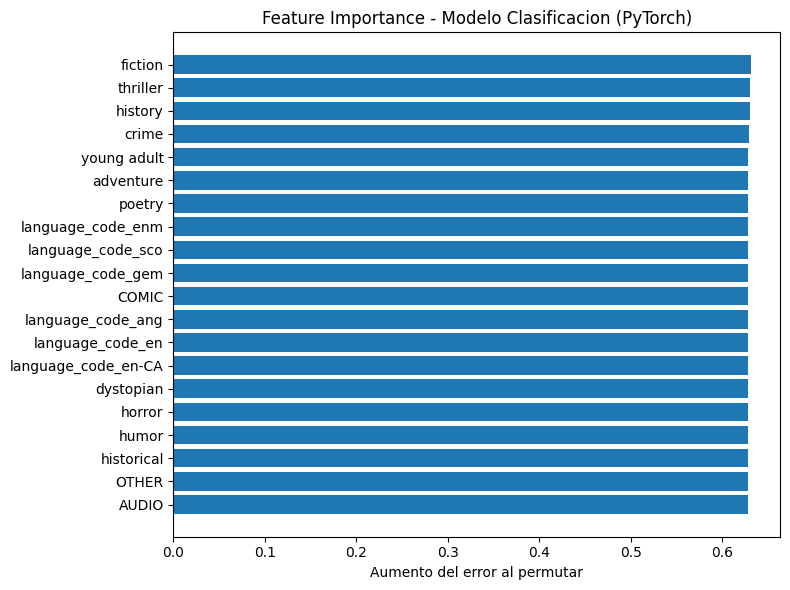

In [24]:
feature_importance_clasificacion = permutation_importance_pytorch(modelo_clasificacion, X_val_scaled, y_val_clasificacion, features, device, metric_fn=accuracy_score, higher_is_better=True, n_repeats=10, clasificacion = True)
plot_feature_importance_pytorch(feature_importance_clasificacion, top_n=20, title="Feature Importance - Modelo Clasificacion (PyTorch)")

Observamos de las matrices de confusion de este modelo que en ningun momento predice las clases minoritarias. No consideramos que sea un modelo adecuado. Los anteriores al menos predecian algunas veces estas clases. 

### Cost + undersampling

In [26]:
mejor_f1 = -np.inf
mejores_parametros = None

for capas_ocultas in parametros_grid_search_rn["capas_ocultas"]:
    for dropout in parametros_grid_search_rn["dropout"]:
        for lr in parametros_grid_search_rn["lr"]:
            for activacion in parametros_grid_search_rn["funcion_activacion"]:

                print(f"Probando: {capas_ocultas}, dropout={dropout}, lr={lr}, activacion={activacion.__name__}")
                modelo = MLP_clasificacion(input_size=X_sub.shape[1], hidden_layers=capas_ocultas, n_classes=5, activation=activacion, dropout=dropout).to(device)

                f1 = run_grid_search_pytorch_clasificacion(modelo=modelo, learning_rate=lr, model_name="MLP Clasificacion", X_train=X_sub_undersampling, y_train=y_sub_clasificacion_undersampling, X_val=X_val_scaled, y_val=y_val_clasificacion, device=device, epochs=30, pesos = pesos_undersampling_cost)

                if f1 > mejor_f1:
                    mejor_f1 = f1
                    mejores_parametros = {"capas_ocultas": capas_ocultas, "dropout": dropout, "lr": lr, "activacion": activacion}

print(f"\nMejores parametros: {mejores_parametros}")

Probando: [128, 64], dropout=0.0, lr=0.01, activacion=ReLU


PyTorch:   0%|          | 0/30 [00:00<?, ?epoca/s]

PyTorch: 100%|██████████| 30/30 [00:43<00:00,  1.45s/epoca, epoch=30]


Probando: [128, 64], dropout=0.0, lr=0.01, activacion=LeakyReLU


PyTorch: 100%|██████████| 30/30 [00:44<00:00,  1.50s/epoca, epoch=30]


...

Probando: [256, 128, 64], dropout=0.4, lr=0.0001, activacion=ReLU


PyTorch: 100%|██████████| 30/30 [00:42<00:00,  1.42s/epoca, epoch=30]


Probando: [256, 128, 64], dropout=0.4, lr=0.0001, activacion=LeakyReLU


PyTorch: 100%|██████████| 30/30 [00:42<00:00,  1.42s/epoca, epoch=30]



Mejores parametros: {'capas_ocultas': [256, 128], 'dropout': 0.2, 'lr': 0.001, 'activacion': <class 'torch.nn.modules.activation.LeakyReLU'>}


PyTorch:   0%|          | 0/100 [00:00<?, ?epoca/s]

PyTorch: 100%|██████████| 100/100 [06:18<00:00,  3.79s/epoca, epoch=100]


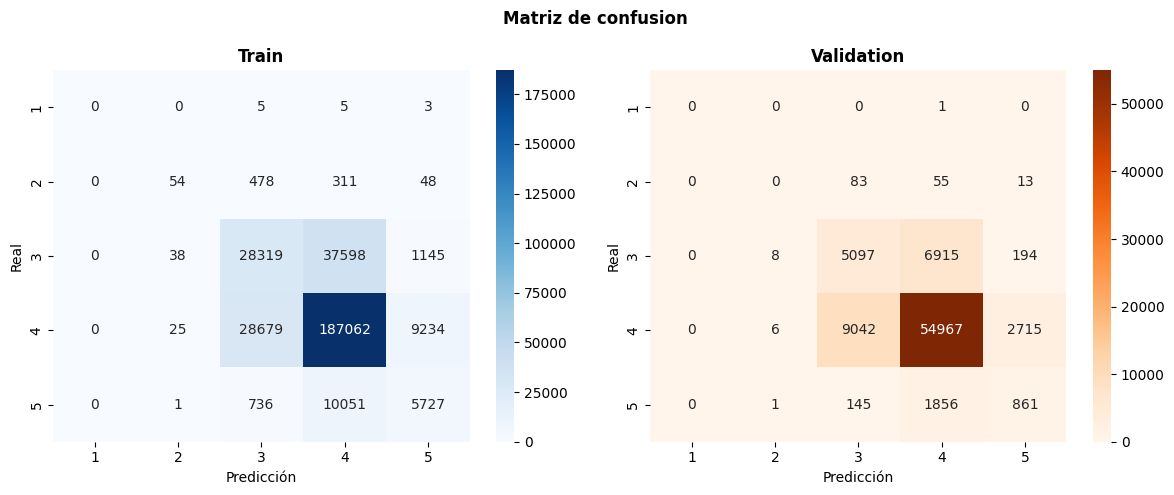

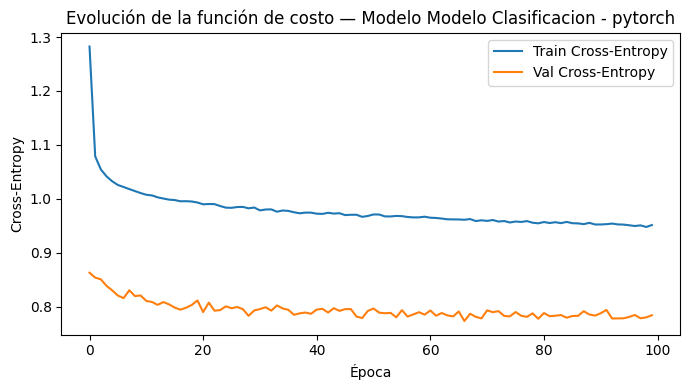

              Train  Validation
Accuracy   0.714534    0.743359
Precision  0.418888    0.288800
Recall     0.332162    0.308353
F1_score   0.344567    0.296972


In [27]:
modelo_clasificacion = MLP_clasificacion(input_size = X_train_scaled.shape[1], hidden_layers = mejores_parametros["capas_ocultas"], n_classes = 5, activation = mejores_parametros["activacion"], dropout = mejores_parametros["dropout"]).to(device)
metricas_train, metricas_val = run_experiment_pytorch_clasificacion(modelo_clasificacion, "Modelo Clasificacion", X_train_undersampling, y_train_undersampling, X_val_scaled, y_val_clasificacion, device, learning_rate = mejores_parametros["lr"], pesos = pesos_undersampling_cost)
tabla_metricas_mlp_clasificacion_undersampling = tabla_metricas(metricas_train, metricas_val, ["Accuracy", "Precision", "Recall", "F1_score"])
print(tabla_metricas_mlp_clasificacion_undersampling)

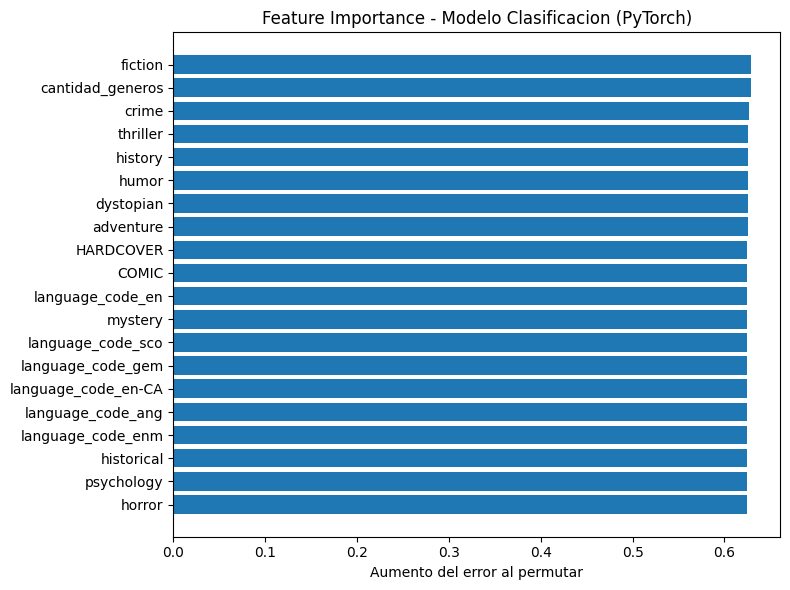

In [28]:
feature_importance_clasificacion = permutation_importance_pytorch(modelo_clasificacion, X_val_scaled, y_val_clasificacion, features, device, metric_fn=accuracy_score, higher_is_better=True, n_repeats=10, clasificacion = True)
plot_feature_importance_pytorch(feature_importance_clasificacion, top_n=20, title="Feature Importance - Modelo Clasificacion (PyTorch)")

Este modelo presenta metricas similares a las anteriores, con menos generalizacion en precision. 

# Comparacion de modelos

In [ ]:
print("Comparacion de tablas de metricas")

print("\nRANDOM FOREST")
print("Regresion")
display(tabla_metricas_rf_regresion)
print("\nClasificacion undersampling + cost")
display(tabla_metricas_rf_clasificacion_undersampling_cost)
print("\nClasificacion cost")
display(tabla_metricas_rf_clasificacion_cost)

print("\nXGBOOST")
print("Regresion")
display(tabla_metricas_xgboost_regresion)
print("\nClasificacion undersampling + cost")
display(tabla_metricas_xgb_clasificacion_undersampling_cost)
print("\nClasificacion cost")
display(tabla_metricas_xgb_clasificacion_cost)

print("\nRED NEURONAL")
print("Regresion")
display(tabla_metricas_mlp_regresion)
print("\nClasificacion undersampling + cost")
display(tabla_metricas_mlp_clasificacion)
print("\nClasificacion cost")
display(tabla_metricas_mlp_clasificacion_undersampling)

Comparacion de tablas de metricas

RANDOM FOREST
Regresion


,Train,Validation
MSE,0.094564,0.111370
RMSE,0.307512,0.333722
MAE,0.235520,0.256799
R²,0.331328,0.214816



Clasificacion undersampling + cost


,Train,Validation
Accuracy,0.784614,0.768823
Precision,0.787792,0.298183
Recall,0.409233,0.288730
F1,0.464159,0.292752



Clasificacion cost


...

,Train,Validation
MSE,0.116485,0.116650
RMSE,0.341299,0.341541
MAE,0.266608,0.266592
R²,0.176318,0.177591



Clasificacion undersampling + cost


,Train,Validation
Accuracy,0.777935,0.756720
Precision,0.516347,0.286244
Recall,0.376618,0.293524
F1_score,0.396881,0.289051



Clasificacion cost


,Train,Validation
Accuracy,0.714534,0.743359
Precision,0.418888,0.288800
Recall,0.332162,0.308353
F1_score,0.344567,0.296972


# Comparación de modelos y conclusiones

## Regresión

Los tres modelos logran una buena generalización (resultados de train y val muy cercanos), con la excepción de Random Forest que presenta el gap más pronunciado. <br>A pesar de que las métricas hayan mejorado con respecto al baseline, la diferencia no es muy notoria.

En los tres modelos obtenemos un R² de ~0.22 (excepto la red neuronal, que cae a 0.178), lo que significa que explican aproximadamente el 20-22% de la variabilidad del rating. 
El RMSE de ~0.33 implica un error de ±0.33 estrellas en promedio.

XGBoost es el modelo con mejor balance entre métricas y generalización. Random Forest tiene el mejor R² en validación (0.215) pero con 
mayor diferencia entre train y val, no sabemos como se va a comportar con datos desconocidos. La red neuronal es la que peor performa en 
regresión (R² val 0.178), aunque sigue generalizando bien (train y val casi idénticos: 0.176 vs 0.178).

## Clasificación

Con respecto al baseline de regresion logistica, las metricas mejoraron. Sin embargo, le sigue costando a los modelos predecir las clases minoritarias. <br>
La diferencia de metricas entre train y val no es por overfitting, sino porque las metricas de train fueron calculadas sobre el conjunto con datos mas balanceados, por lo que performa mejor.

Random Forest: <br>
Con undersampling + cost: accuracy alta (0.769) pero F1 macro bajo (0.293) — el modelo 
aprende bien las clases mayoritarias pero no generaliza a las minoritarias. <br>
Con solo cost: accuracy aún más alta (0.804) pero F1 macro peor (0.267) — el modelo se 
vuelca todavía más a predecir las clases frecuentes. <br>

XGBoost: <br>
Con undersampling + cost: F1 macro en validación de 0.299, el más alto entre los modelos 
de árboles. <br>Con solo cost: F1 macro de 0.289, resultado similar. <br>

Red Neuronal: <br>
Con undersampling + cost: F1 macro de 0.289 en val — comparable a XGBoost en esta 
configuración, una mejora notable respecto a iteraciones anteriores. <br>
Con solo cost: F1 macro de 0.297 en val, el mejor resultado individual de clasificación 
de toda esta fase. <br>

De esta fase, el mejor modelo de clasificación es **XGBoost con undersampling + cost**.

## Próximos pasos

En la próxima fase, vamos a tratar de manera más fina las features de autor y publisher, y utilizar 
la sinopsis. Es decir, mantener estos modelos pero mejorando las 
features.